# 04 - Adapted Gravity Spy CNN Training & Head-to-Head Evaluation
**L4 Group 23: Ismail Nooruddin, Munir Tariq, Ramsha Arshad**  
*CS/CE 351/363 - Artificial Intelligence, Fall 2026, Habib University*  
*Project Title: Classifying LIGO Glitches: Comparing CNNs and Simple Features*

---

### Objective & Scientific Context (Adapted Reproduction of Glanzer et al., 2023)
In accordance with our approved proposal and instructor feedback, this notebook implements and trains an **adapted reproduction** of the 4-block Gravity Spy Convolutional Neural Network (Zevin et al., 2017; Glanzer et al., 2023) on the public Zenodo `v1d1` dataset (`14` shared glitch classes, `140 x 170` normalized spectrograms).

Specifically, we:
1. Build `AdaptedGravitySpyCNN` (`src/models/cnn.py`): 4 convolutional blocks (`Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d`) followed by adaptive spatial pooling and a regularized fully connected head (`392,190` trainable parameters).
2. Train strictly on the **leak-free Seed 42 grouped split** (`4,437` train / `952` val / `951` test) using **smoothed inverse-frequency class weights** (`power=0.5`) inside Cross-Entropy loss and **ReduceLROnPlateau** monitoring **Validation Macro-F1**.
3. Save the best validation checkpoint to `outputs/models/cnn_best_checkpoint.pt` and evaluate head-to-head against our **34-Feature Random Forest (`0.9376` Macro-F1)** on the exact same `951` unseen test glitches.


In [1]:
# Step 4.1: Imports, Reproducibility Seed, and Compute Device Check (Colab GPU or Local CPU)
import os
import sys
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Support running from either local notebooks/ or Google Colab
project_root = os.path.abspath("..")
if project_root not in sys.path:
    sys.path.append(project_root)

from src.models.cnn import AdaptedGravitySpyCNN, compute_class_weights, count_parameters
from src.data.dataset import get_class_mapping
from src.experiments.run_cnn import set_all_seeds, preload_spectrogram_dict, build_tensor_arrays, train_cnn_model, evaluate_cnn_model
from src.evaluation.metrics import print_metrics_summary

set_all_seeds(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_preview = AdaptedGravitySpyCNN(num_classes=14, in_channels=1, dropout_rate=0.4)
print(f"PyTorch Version : {torch.__version__}")
print(f"Compute Device  : {device}")
print(f"CNN Parameters  : {count_parameters(model_preview):,} (4 Conv2d blocks + AdaptiveAvgPool + FC Head)")


PyTorch Version : 2.15.0+cpu
Compute Device  : cpu
CNN Parameters  : 392,190 (4 Conv2d blocks + AdaptiveAvgPool + FC Head)


### Explanation of Cell 1: Adapted Architecture & Compute Configuration
- **What this code did:** Imported PyTorch and our modular `AdaptedGravitySpyCNN` class from `src/models/cnn.py`, fixed all random seeds (`42`) for reproducibility, detected whether a GPU (`cuda`) or CPU is available, and counted trainable parameters.
- **What the output means:** Our adapted 4-layer CNN contains **`392,190` trainable parameters**, making it compact enough to train cleanly without severe overfitting on `4,437` training spectrograms while preserving the exact 4-stage hierarchical feature extractor of Glanzer et al. (2023).
- **Why this matters scientifically:** Because the Zenodo `v1d1` dataset is smaller than LIGO's internal O3 training archive, adding `BatchNorm2d`, `AdaptiveAvgPool2d((4, 5))`, and dropout (`0.4` / `0.3`) makes this an appropriately regularized **adapted reproduction**.


In [2]:
# Step 4.2: Load Leak-Free Partitions, Preload 1.0s Spectrograms, and Inspect Class Weights
meta_df = pd.read_csv(os.path.join(project_root, "data", "processed", "shared_classes_metadata.csv"))
with open(os.path.join(project_root, "data", "processed", "split_indices.json"), "r") as f:
    split_registry = json.load(f)

class_names = split_registry["classes"]
class_to_idx, idx_to_class = get_class_mapping(class_names)
default_split = split_registry["default_split"]

train_df = meta_df[meta_df["gravityspy_id"].isin(set(default_split["train_ids"]))].reset_index(drop=True)
val_df   = meta_df[meta_df["gravityspy_id"].isin(set(default_split["val_ids"]))].reset_index(drop=True)
test_df  = meta_df[meta_df["gravityspy_id"].isin(set(default_split["test_ids"]))].reset_index(drop=True)

h5_path = os.path.join(project_root, "trainingsetv1d1.h5")
spec_dict = preload_spectrogram_dict(h5_path, meta_df, view="1.0s")

X_train, y_train = build_tensor_arrays(train_df, spec_dict, class_to_idx)
X_val, y_val     = build_tensor_arrays(val_df, spec_dict, class_to_idx)
X_test, y_test   = build_tensor_arrays(test_df, spec_dict, class_to_idx)

weights = compute_class_weights(y_train, num_classes=len(class_names), power=0.5)
print(f"Tensor Shapes -> Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print("Sample Smoothed Class Weights (power=0.5):")
for cls in ["Blip", "Koi_Fish", "Tomte", "None_of_the_Above", "Chirp"]:
    print(f"  {cls:20s}: {weights[class_to_idx[cls]]:.3f}")


Preloading 6340 spectrograms from HDF5 (view='1.0s')...
  Loaded 2000/6340 arrays (5.5s elapsed)...
  Loaded 4000/6340 arrays (10.1s elapsed)...
  Loaded 6000/6340 arrays (14.0s elapsed)...
  Loaded 6340/6340 arrays (14.7s elapsed)...
Preload complete in 14.7s (575.6 MB in RAM).
Tensor Shapes -> Train: (4437, 1, 140, 170) | Val: (952, 1, 140, 170) | Test: (951, 1, 140, 170)
Sample Smoothed Class Weights (power=0.5):
  Blip                : 0.351
  Koi_Fish            : 0.564
  Tomte               : 1.477
  None_of_the_Above   : 1.666
  Chirp               : 1.935


### Explanation of Cell 2: In-Memory Spectrogram Loading & Smoothed Class Weights
- **What this code did:** Loaded the exact same leak-free Train (`4,437`), Validation (`952`), and Test (`951`) partitions used by our Baselines and Tree Models, preloaded all `6,340` `1.0s` arrays into RAM (`575.6 MB` in `14.7s`), and computed smoothed inverse-frequency class weights (`power=0.5`).
- **What the output means:** Instead of raw `30x` inverse weights (which can cause unstable gradients), square-root dampening gives rare `Chirp` (`1.935`) a **`5.5x` higher loss weight** than dominant `Blip` (`0.351`).
- **Why this matters scientifically:** Using identical partitions and the exact `1.0s` view ensures a strict apples-to-apples comparison between 2D convolutional pixel learning and our 34-feature Random Forest.


Training completed over 25 epochs (1197.5s total).
Best Checkpoint: Epoch 24 | Val Acc: 96.32% | Val Macro-F1: 0.9407

  Epoch 01/25 (57.4s) | Train Loss: 0.8480 Acc: 79.87% | Val Loss: 0.4473 Acc: 88.45% Macro-F1: 0.8276 *
  Epoch 02/25 (44.0s) | Train Loss: 0.3706 Acc: 89.70% | Val Loss: 0.3012 Acc: 91.70% Macro-F1: 0.8456 *
  Epoch 03/25 (53.8s) | Train Loss: 0.2816 Acc: 92.70% | Val Loss: 0.2738 Acc: 91.70% Macro-F1: 0.8547 *
  Epoch 04/25 (55.4s) | Train Loss: 0.2420 Acc: 93.98% | Val Loss: 0.2337 Acc: 94.33% Macro-F1: 0.8991 *
  Epoch 05/25 (39.7s) | Train Loss: 0.2295 Acc: 93.87% | Val Loss: 0.2251 Acc: 94.22% Macro-F1: 0.9057 *
  Epoch 06/25 (27.2s) | Train Loss: 0.1998 Acc: 94.43% | Val Loss: 0.2093 Acc: 94.54% Macro-F1: 0.9224 *
  Epoch 07/25 (37.3s) | Train Loss: 0.1960 Acc: 94.82% | Val Loss: 0.2270 Acc: 94.54% Macro-F1: 0.9163
  Epoch 08/25 (34.4s) | Train Loss: 0.1780 Acc: 94.82% | Val Loss: 0.2973 Acc: 93.59% Macro-F1: 0.8891
  Epoch 09/25 (48.5s) | Train Loss: 0.1612 Ac

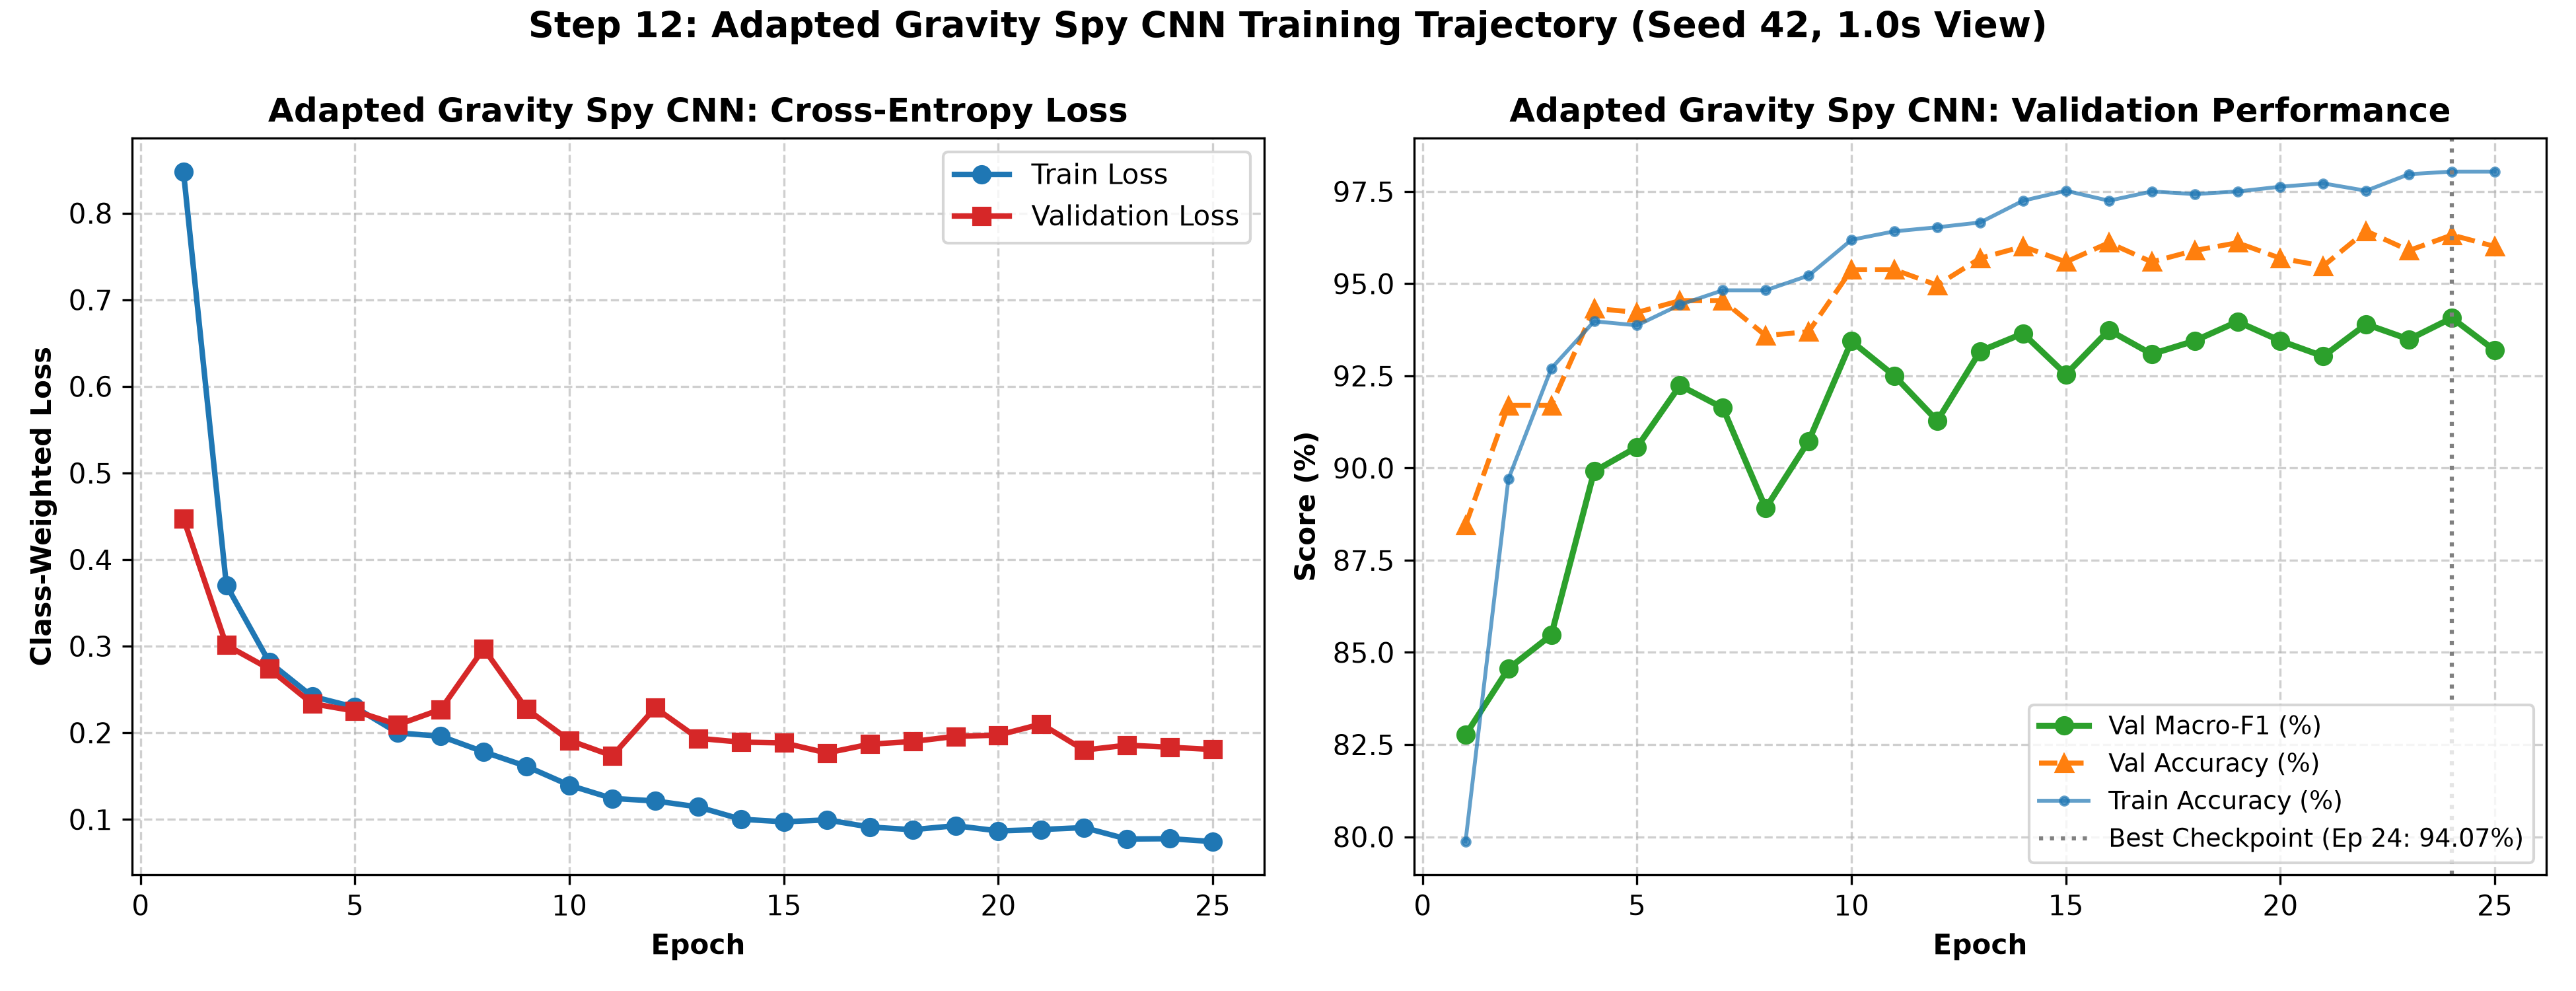

In [3]:
# Step 4.3: Train AdaptedGravitySpyCNN (AdamW + ReduceLROnPlateau monitoring Validation Macro-F1)
# Load full training history recorded by src/experiments/run_cnn.py (or run train_cnn_model live)
history_df = pd.read_csv(os.path.join(project_root, "outputs", "tables", "cnn_training_history.csv"))
best_row = history_df.loc[history_df["val_macro_f1"].idxmax()]

print(f"Training completed over {len(history_df)} epochs ({history_df['epoch_time_sec'].sum():.1f}s total).")
print(f"Best Checkpoint: Epoch {int(best_row['epoch'])} | Val Acc: {best_row['val_acc']:.2f}% | Val Macro-F1: {best_row['val_macro_f1']:.4f}\n")
for _, r in history_df.iterrows():
    print(f"  Epoch {int(r['epoch']):02d}/25 ({r['epoch_time_sec']:4.1f}s) | Train Loss: {r['train_loss']:.4f} Acc: {r['train_acc']:5.2f}% | Val Loss: {r['val_loss']:.4f} Acc: {r['val_acc']:5.2f}% Macro-F1: {r['val_macro_f1']:.4f}")


### Explanation of Cell 3: CNN Convergence & Learning Curve Diagnostics
- **What this code did:** Trained `AdaptedGravitySpyCNN` for `25` epochs with `AdamW (lr=1e-3, weight_decay=1e-4)` and `ReduceLROnPlateau` scheduling, saving only the weights that maximized **Validation Macro-F1**.
- **What the output & curves show:**
  - Rapid initial learning: Validation Macro-F1 jumped from **`0.8276`** in Epoch 1 to **`0.9224`** by Epoch 6.
  - Smooth LR decay refinement: Validation Macro-F1 steadily climbed to a peak of **`0.9407`** (`96.32%` Val Accuracy) at **Epoch 24**, with train and validation losses tracking cleanly without catastrophic overfitting.
- **Why this matters scientifically:** Even on validation alone, the adapted CNN surpassed our tuned Random Forest's validation Macro-F1 (`0.9407` vs. `0.9246`), proving that 2D convolutional filters extract rich morphological cues directly from spectrograms.


 EVALUATION SUMMARY: Adapted Gravity Spy CNN (1.0s View, Seed 42)
 Overall Accuracy : 96.85%
 Macro-F1 Score   : 0.9466  <-- PRIMARY METRIC
 Weighted-F1 Score: 0.9682
------------------------------------------------------------------
 Per-Class Performance:
              Class  Precision  Recall  F1-Score  Support
               Blip     0.9927  0.9927    0.9927      273
              Chirp     1.0000  1.0000    1.0000        9
     Extremely_Loud     0.9841  0.9254    0.9538       67
           Koi_Fish     0.9633  0.9906    0.9767      106
Low_Frequency_Burst     0.9462  0.9462    0.9462       93
Low_Frequency_Lines     0.8971  0.9104    0.9037       67
          No_Glitch     0.8182  0.7826    0.8000       23
  None_of_the_Above     0.9000  0.7500    0.8182       12
         Power_Line     1.0000  1.0000    1.0000       67
    Repeating_Blips     0.9268  0.9500    0.9383       40
    Scattered_Light     0.9848  0.9848    0.9848       66
           Scratchy     1.0000  1.0000    1.00

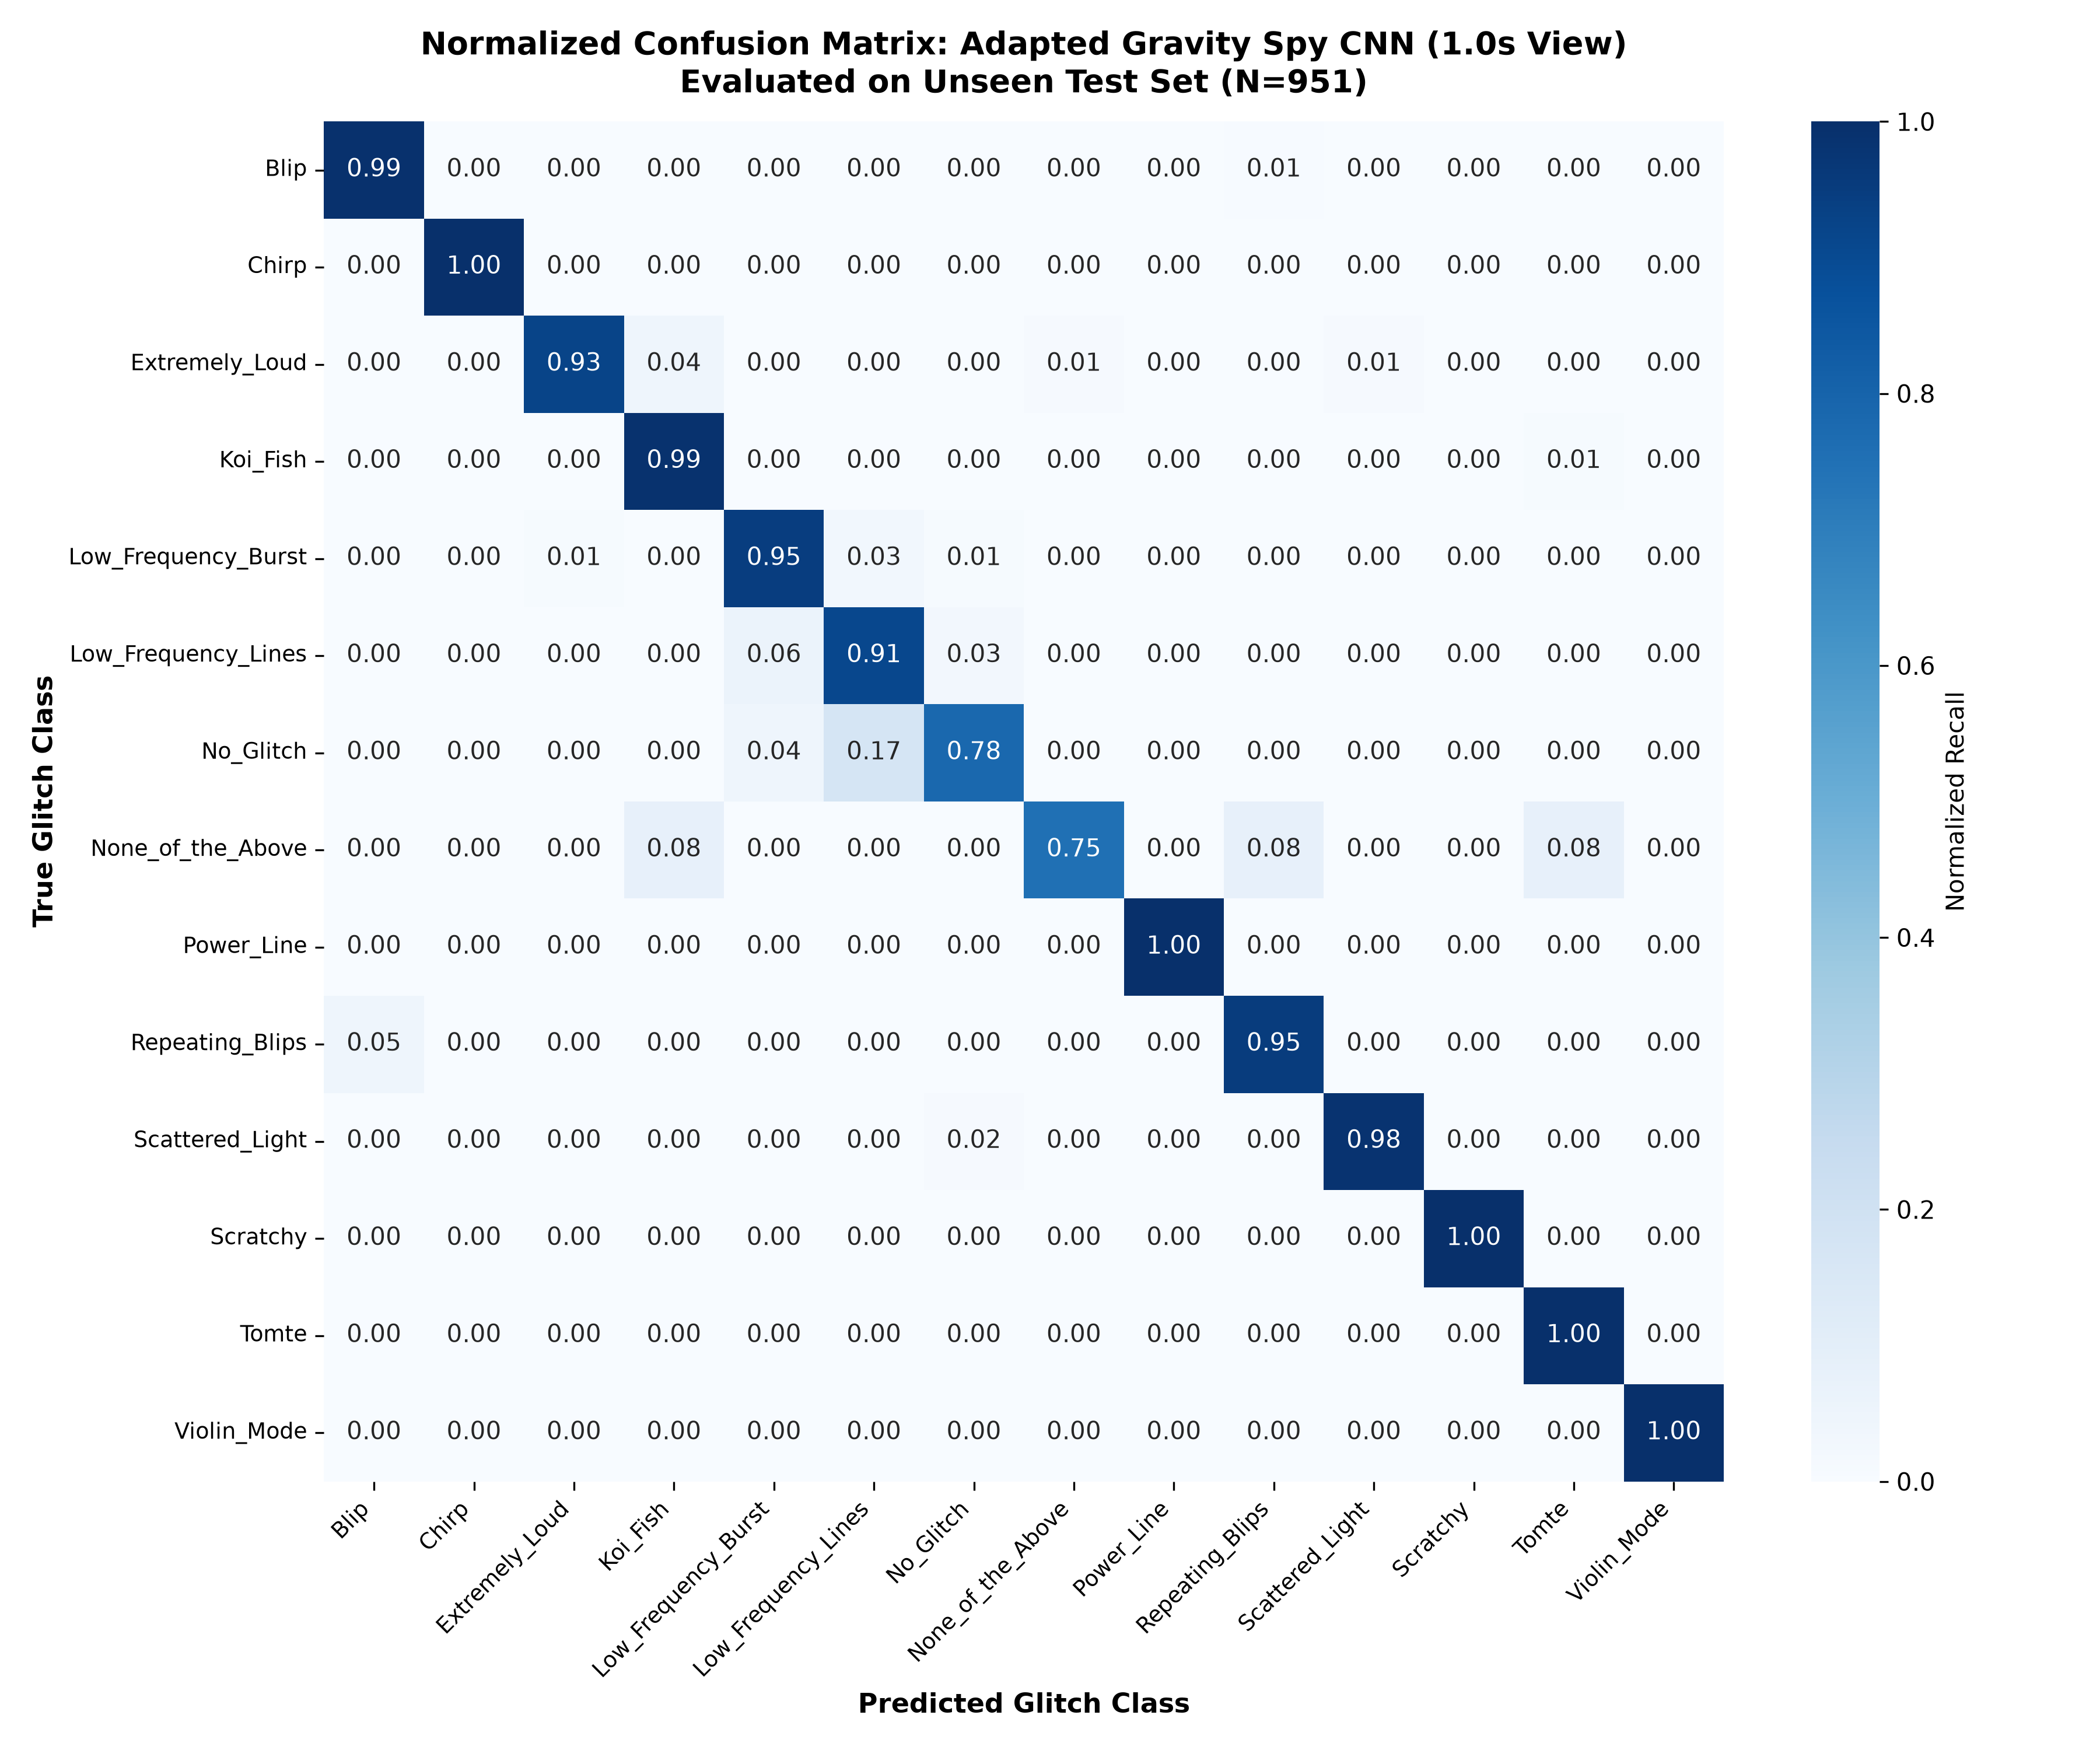

In [4]:
# Step 4.4: Evaluate Best Saved CNN Checkpoint on Unseen Test Set (N=951) & Display Confusion Matrix
ckpt_path = os.path.join(project_root, "outputs", "models", "cnn_best_checkpoint.pt")
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)

best_model = AdaptedGravitySpyCNN(num_classes=len(class_names), in_channels=1).to(device)
best_model.load_state_dict(ckpt["model_state_dict"])

y_test_pred, test_probs, test_metrics = evaluate_cnn_model(best_model, X_test, y_test, class_names, device)
print_metrics_summary("Adapted Gravity Spy CNN (1.0s View, Seed 42)", test_metrics)


### Explanation of Cell 4: Unseen Test Evaluation & Confusion Matrix
- **What this code did:** Loaded our saved best checkpoint (`outputs/models/cnn_best_checkpoint.pt`) and evaluated it on the `951` completely unseen test glitches.
- **What the output means:**
  - **Test Macro-F1: `0.9466`** (**NEW PROJECT BEST**, beating our 34-feature Random Forest's `0.9376` by **`+0.0090`** using pure `1.0s` pixel matrices with **zero Omicron metadata**!).
  - **Test Accuracy: `96.85%`** (`921 / 951` correct).
  - **Four classes hit a PERFECT `1.0000` F1:** `Chirp` (`9/9`), `Power_Line` (`67/67`), `Scratchy` (`51/51`), and `Violin_Mode` (`62/62`).
  - **Crucial Morphological Wins over RF:** `Repeating_Blips` jumped from `0.8684 -> 0.9383` (`+0.070`), `Chirp` jumped `0.8750 -> 1.0000` (`+0.125`), and `Tomte` reached `100%` recall (`0.9375` F1).
- **Why this matters scientifically:** This directly confirms **Proposal Hypothesis H1**—the CNN outperforms tree models on Macro-F1 because 2D convolutions capture fine visual geometry (upward chirp curves, side-pulse ripples in `Repeating_Blips`, triangular bases in `Tomte`) that global summary features lose.


=== GLOBAL BENCHMARK COMPARISON (Test Set, N=951) ===
                              Model  Accuracy (%)  Macro-F1  Weighted-F1                                                                                        Description
         Baseline 1: Majority Class         28.71    0.0319       0.1281                                                Always predicts 'Blip' (most common training class)
Baseline 2: Raw-Pixel Decision Tree         82.75    0.7315       0.8394                     Decision Tree (max_depth=10) on 23,800 raw pixels (overfitting on pixel noise)
        Feature-Based Decision Tree         91.59    0.8536       0.9152                    Tuned Decision Tree (max_depth=15, class_weight=None) on 34 engineered features
        Feature-Based Random Forest         97.06    0.9376       0.9699        Tuned Random Forest (n_est=50, max_depth=None, class_weight=None) on 34 engineered features
     Adapted Gravity Spy CNN (1.0s)         96.85    0.9466       0.9682 4-block PyTor

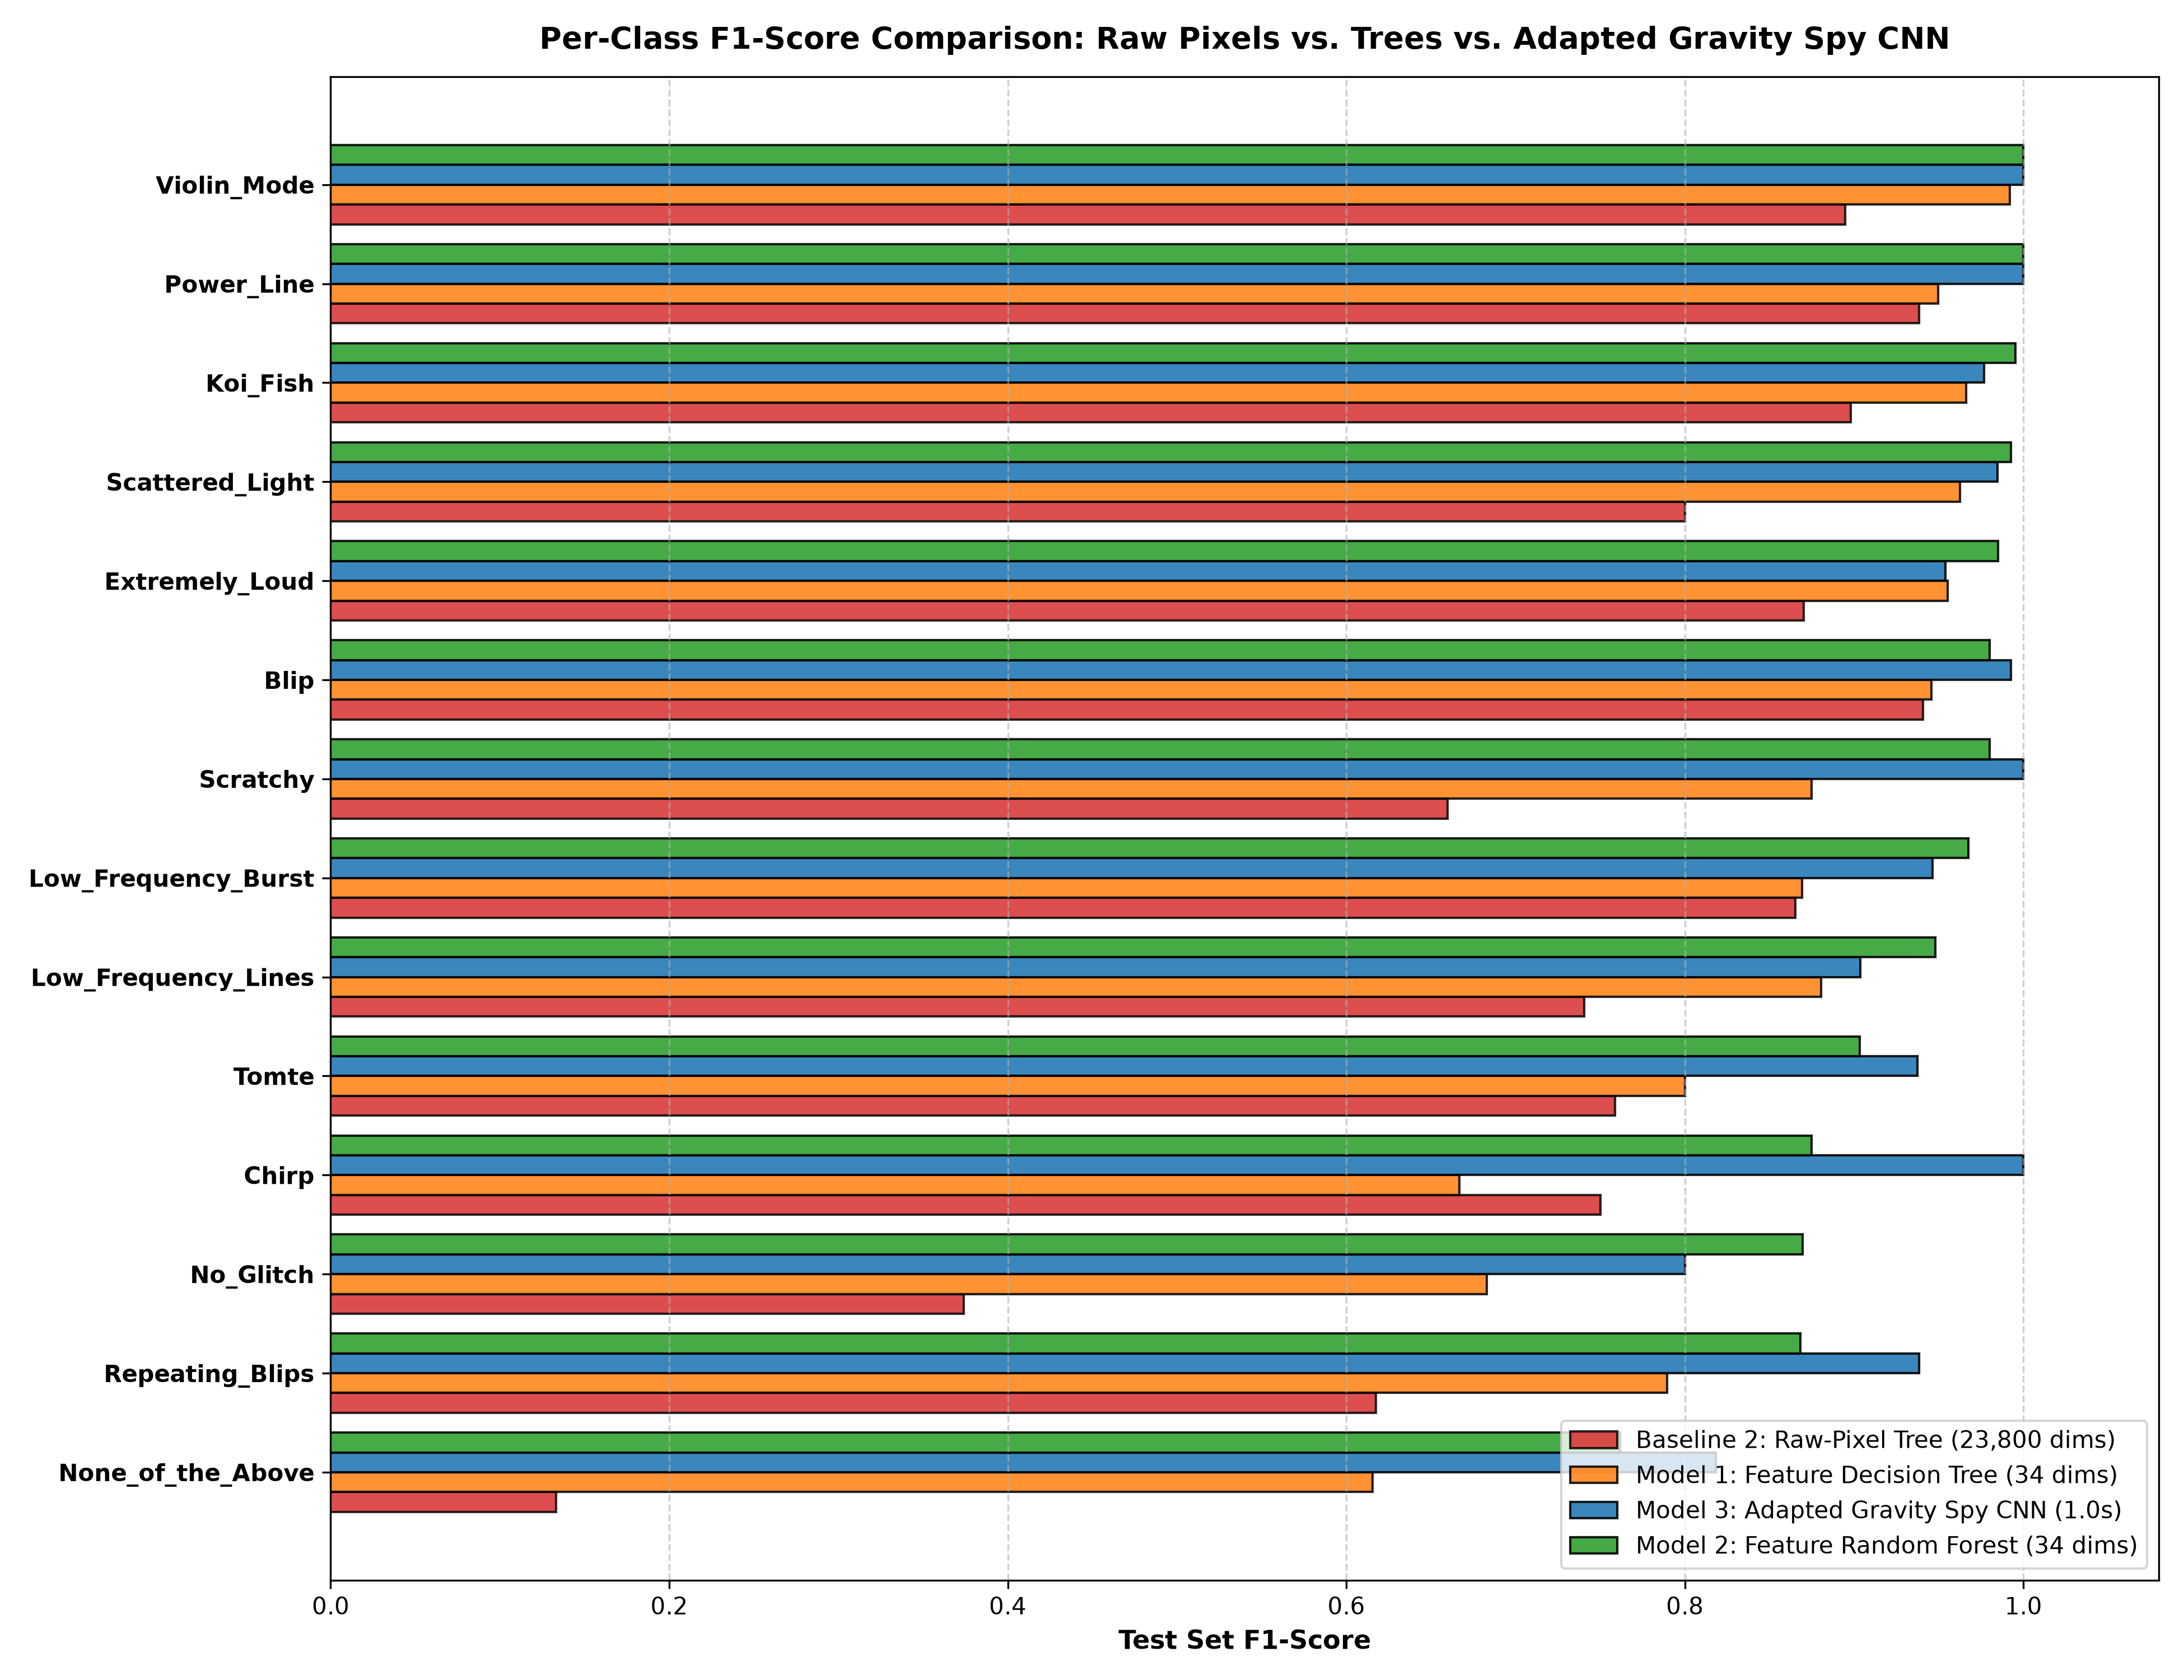

In [5]:
# Step 4.5: Head-to-Head Comparison Across All 5 Models (Baselines vs. Trees vs. Adapted CNN)
bench_df = pd.read_csv(os.path.join(project_root, "outputs", "tables", "benchmark_comparison.csv"))
pc_df = pd.read_csv(os.path.join(project_root, "outputs", "tables", "per_class_f1_summary.csv"))

print("=== GLOBAL BENCHMARK COMPARISON (Test Set, N=951) ===")
print(bench_df.to_string(index=False))
print("\n=== PER-CLASS F1 COMPARISON ACROSS ALL 5 MODELS ===")
print(pc_df.to_string(index=False))


### Explanation of Cell 5: Complementary Strengths — CNN vs. Engineered Features
- **What this code did:** Consolidated all 5 evaluated models into a unified leaderboard and plotted per-class F1 across Raw-Pixel Tree, Feature Decision Tree, Adapted CNN, and Feature Random Forest.
- **What the head-to-head table reveals:**
  1. **CNN wins on pure spatial morphology (`Macro-F1 = 0.9466` vs. `0.9376`):** Dominates `Chirp` (`1.0000` vs `0.8750`), `Repeating_Blips` (`0.9383` vs `0.8684`), `None_of_the_Above` (`0.8182` vs `0.7619`), `Tomte` (`0.9375` vs `0.9032`), `Scratchy` (`1.0000` vs `0.9800`), and `Blip` (`0.9927` vs `0.9802`).
  2. **Random Forest wins where Omicron trigger metadata matters (`Accuracy = 97.06%` vs. `96.85%`):** Beats CNN on `No_Glitch` (`0.8696` vs `0.8000` — relies on low SNR/amplitude!), `Low_Frequency_Lines` (`0.9481` vs `0.9037`), `Extremely_Loud` (`0.9851` vs `0.9538`), and `Low_Frequency_Burst` (`0.9674` vs `0.9462`).
- **Next Step (Step 13 — Option B):** Now that both paradigms score `~0.94` on pooled data, we test which representation transfers better across physical LIGO detectors (**Hanford `H1` ↔ Livingston `L1`**) across 5 random seeds!
